# ĐỊNH GIÁ ĐẤT NỀN / ĐẤT THỔ CƯ – BÌNH DƯƠNG CŨ (trọng tâm Thủ Dầu Một)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

Ở Thủ Dầu Một, nhiều người mua **đất trống** để tự xây hoặc để đầu tư, không mua nhà có sẵn. Giá đất cũng là phần lớn giá trị của một căn nhà phố. Notebook này xây mô hình **định giá lô đất ở** theo đúng quy trình của notebook nhà phố:

1. Dữ liệu thật: tin **bán đất** trên Chợ Tốt Nhà (toàn Bình Dương cũ) và alonhadat (Thủ Dầu Một).
2. Làm sạch: sửa diện tích nhập nhầm, loại tin trùng, loại tin không phải giá đất ở thị trường; gom tin gần trùng.
3. Mô hình học máy trên **log(đơn giá đất)**, kiểm định chéo lặp chia theo nhóm, chọn mô hình bằng quy tắc thống kê.
4. Khoảng giá 80% và chẩn đoán giá rao của các lô đất ở Thủ Dầu Một.

> Khoảng 3 phút.

**Phạm vi kiến thức** (toàn bộ notebook này là **phần mở rộng** của đề tài; notebook chính `2324801030095.ipynb` mới là bài làm theo môn học):

| Trong môn học (bài giảng / thực hành) | Ngoài môn học (nâng cao) |
|---|---|
| Tiền xử lý: thiếu, trùng, ngoại lai (TH4); trích đặc trưng từ mô tả (TH6); chia train/test; hồi quy tuyến tính có phạt (Ridge, mô hình được chọn); kiểm định chéo K-fold; MAE, MAPE, R² | LightGBM, stacking với mô hình chữ; giá khu vực theo láng giềng gần nhất; chia fold theo nhóm; khoảng tin cậy bootstrap; khoảng giá 80% từ sai số ngoài-fold |

In [1]:
import re, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(GOC / "src"))
RAW, PROC, MODEL_DIR, KET_QUA = GOC / "data" / "raw", GOC / "data" / "processed", GOC / "model", GOC / "ket_qua"
from mo_hinh_gia import (khong_dau, ten_phuong, ten_quan, ten_duong, trich_dac_trung_chu, nhom_gan_trung, MoHinhGia, XepChongChu,
                         BaselineDonGiaPhuong, du_doan_cheo_lap, sai_so_tung_can, ktc_bootstrap, bang_danh_gia,
                         hieu_chinh_khoang, phan_vi_cho, muc_gia)
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import BallTree
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RANDOM_STATE, SO_LAN = 42, 3

raw_ct = pd.read_csv(RAW / "chotot_dat_raw.csv")
raw_al = pd.read_csv(RAW / "alonhadat_dat_tdm_raw.csv")
print(f"Chợ Tốt (đất): {len(raw_ct)} tin, thu thập {raw_ct['ngay_thu_thap'].iloc[0]} | alonhadat (đất, Thủ Dầu Một): {len(raw_al)} tin")
display(pd.crosstab(raw_ct["loai_dat"], raw_ct["loai_tin"]))

Chợ Tốt (đất): 1214 tin, thu thập 2026-11-17 | alonhadat (đất, Thủ Dầu Một): 291 tin


loai_tin,ban,cho_thue
loai_dat,,
Đất công nghiệp,14,2
Đất nông nghiệp,44,3
Đất nền dự án,74,1
Đất thổ cư,1064,12


**Quan sát:** Chợ Tốt có vài tin **cho thuê** đất (giá theo tháng) – phải loại. Đa số tin là **đất thổ cư**; đất nền dự án là một phần nhỏ; **đất nông nghiệp** và **đất công nghiệp** rất ít và là thị trường khác hẳn (không được xây nhà ở ngay), nên mô hình này chỉ định giá **đất ở** (thổ cư và nền dự án).

## Bước 1: Hợp nhất 2 nguồn

In [2]:
def so(x):
    if pd.isna(x):
        return np.nan
    m = re.search(r"\d+(?:[.,]\d+)?", str(x))
    return float(m.group().replace(",", ".")) if m else np.nan

c = raw_ct[raw_ct["loai_tin"] == "ban"]
dd = c["dac_diem"].fillna("")
cung_toa_do = c.groupby(["lat", "lon"])["id"].transform("size")
C = pd.DataFrame({
    "nguon": "chotot", "id": c["id"].astype(str), "url": c["url"], "ngay_dang": c["ngay_dang"], "tieu_de": c["tieu_de"], "mo_ta": c["mo_ta"].fillna(""),
    "gia_ty": c["gia"] / 1e9, "dt_dat": c["dt_dat"], "ngang": c["ngang"], "dai": c["dai"],
    "loai_dat": c["loai_dat"].map({"Đất thổ cư": "tho_cu", "Đất nền dự án": "nen_du_an", "Đất nông nghiệp": "nong_nghiep", "Đất công nghiệp": "cong_nghiep"}),
    "mat_tien_duong": (dd.str.contains("Mặt tiền") | (c["mat_duong_chinh"].astype(str) == "True")).astype(float),
    "hem_xe_hoi_form": dd.str.contains("Hẻm xe hơi").astype(float),
    "tho_cu_toan_bo": np.where(dd.str.contains("Thổ cư toàn bộ"), 1.0, np.where(dd.str.contains("Thổ cư 1 phần"), 0.0, np.nan)),
    "so_rieng": np.where(c["phap_ly"] == "Đã có sổ", 1.0, np.where(c["phap_ly"].notna(), 0.0, np.nan)),
    "hem_rong": np.nan, "quan": c["quan_huyen"].map(ten_quan), "phuong": c["phuong"].map(ten_phuong), "duong": c["duong"].map(ten_duong),
    "lat": c["lat"], "lon": c["lon"], "toa_do_rieng": (c["dia_chi_ma_vi_tri"].astype(str).str.startswith("osm") | (cung_toa_do <= 3)).astype(int),
})
a = raw_al
kt = a["kich_thuoc"].fillna("").str.replace(",", ".").str.extract(r"([\d.]+)\s*x\s*([\d.]+)").astype(float)
dc = a["dia_chi_cu"].fillna("").str.split(",")
A = pd.DataFrame({
    "nguon": "alonhadat", "id": a["id"].astype(str), "url": a["url"], "ngay_dang": a["ngay_dang"], "tieu_de": a["tieu_de"], "mo_ta": a["mo_ta"].fillna(""),
    "gia_ty": pd.to_numeric(a["gia"]) / 1e9, "dt_dat": a["dt_dat"].map(so), "ngang": kt[0], "dai": kt[1],
    "loai_dat": np.where(a["loai_nha"] == "dat-nen-lien-ke-dat-du-an", "nen_du_an", "tho_cu"),
    "mat_tien_duong": np.nan, "hem_xe_hoi_form": np.nan, "tho_cu_toan_bo": np.nan, "so_rieng": np.nan,
    "hem_rong": a["duong_rong"].map(so), "quan": "thu dau mot",
    "phuong": dc.map(lambda p: ten_phuong(p[1]) if len(p) > 2 else None), "duong": dc.map(lambda p: ten_duong(p[0]) if len(p) > 2 else None),
    "lat": np.nan, "lon": np.nan, "toa_do_rieng": 0,
})
df = pd.concat([C, A], ignore_index=True)
ngoai = df["lat"].notna() & ~(df["lat"].between(10.82, 11.65) & df["lon"].between(106.30, 106.95))
df.loc[ngoai, ["lat", "lon"]] = np.nan; df.loc[ngoai, "toa_do_rieng"] = 0
df["van_ban"] = (df["tieu_de"].fillna("") + " . " + df["mo_ta"]).map(khong_dau)
T = trich_dac_trung_chu(df["van_ban"])
df = pd.concat([df, T], axis=1)
df["ngang"] = df["ngang"].fillna(df["t_ngang"]).fillna(df["t_kt_ngang"]); df["dai"] = df["dai"].fillna(df["t_kt_dai"])
df["hem_rong"] = df["hem_rong"].where(df["hem_rong"].between(1.5, 60)).fillna(df["t_hem_rong"])
df["mat_tien_duong"] = df["mat_tien_duong"].fillna(df["t_mat_tien"])
df["so_rieng"] = df["so_rieng"].fillna(df["t_so_rieng"].where(df["t_so_rieng"] == 1))
df["so_chung"] = df["t_so_chung"].astype(float)
df["t_hem_xe_hoi"] = ((df["t_hem_xe_hoi"] == 1) | (df["hem_xe_hoi_form"] == 1)).astype(int)
tu_rong = pd.cut(df["hem_rong"], [0, 2.5, 3.5, 5, 7, 10, 100], labels=[0, 1, 2, 3, 4, 4.5], right=False).astype(float)
cap = pd.Series(np.where(df["mat_tien_duong"] == 1, 5, np.nan), index=df.index).fillna(tu_rong)
df["cap_loi_vao"] = cap.where(cap.notna(), np.where(df["t_hem_xe_hoi"] == 1, 2, np.where(df["t_hem_nho"] == 1, 0.5, np.nan)))
df["nen_du_an"] = ((df["loai_dat"] == "nen_du_an") | (df["t_kdc"] == 1)).astype(int)
print("Bảng hợp nhất:", df.shape)
df.groupby("nguon")[["dt_dat", "ngang", "dai", "hem_rong", "cap_loi_vao", "so_rieng", "tho_cu_toan_bo", "lat"]].agg(lambda s: s.notna().mean() * 100).round(0).T.rename_axis("% có dữ liệu")

Bảng hợp nhất: (1487, 56)


nguon,alonhadat,chotot
% có dữ liệu,,
dt_dat,100.0,97.0
ngang,93.0,86.0
dai,92.0,78.0
hem_rong,100.0,23.0
cap_loi_vao,100.0,66.0
so_rieng,13.0,60.0
tho_cu_toan_bo,0.0,27.0
lat,0.0,100.0


## Bước 2: Làm sạch
1. **Sửa diện tích nhập nhầm** (ghi chiều dài vào ô diện tích) như notebook nhà phố.
2. **Phạm vi đất ở:** loại đất nông nghiệp/công nghiệp; giữ giá 0,2–100 tỷ, diện tích 40–3.000 m², đơn giá 1–200 triệu/m².
3. **Tin trùng khớp hẳn:** cùng quận, cùng giá, cùng diện tích → giữ 1 (ưu tiên bản Chợ Tốt có tọa độ).
4. **Gán tọa độ** cho tin alonhadat: tọa độ trung vị của tuyến đường (từ tin Chợ Tốt đất + nhà có tọa độ riêng), nếu không có thì tâm phường.
5. **Loại tin không phản ánh giá đất ở thị trường** (ghi lý do vào `data/processed/dat_bi_loai.csv`):

| Quy tắc | Lý do |
|---|---|
| Bán **nhiều lô / cả dự án**, "giá từ", "chỉ từ", "giá chỉ" kèm khoảng giá | Giá đại diện cho cả dự án, không phải một lô |
| Diện tích thổ cư ghi rõ < 50% diện tích đất | Phần lớn là đất vườn, đơn giá thấp hơn hẳn |
| Có nhà trên đất (nhà cấp 4 còn ở được, dãy trọ) | Giá gồm cả nhà / dòng tiền cho thuê, không phải giá đất |
| Đơn giá lệch hơn 3 lần trung vị 15 lô gần nhất | Gần như chắc chắn là lỗi nhập |

In [3]:
nd = df["ngang"] * df["dai"]
ghi_nham = ((df["dt_dat"] - df["dai"]).abs() <= 1) | ((df["dt_dat"] - df["ngang"]).abs() <= 0.5)
sua = nd.between(40, 3000) & (df["dt_dat"].isna() | (ghi_nham & (df["dt_dat"] < 0.6 * nd)))
df.loc[sua, "dt_dat"] = nd[sua]
print("Sửa diện tích:", int(sua.sum()), "tin")

n0 = len(df)
df = df[df["loai_dat"].isin(["tho_cu", "nen_du_an"])]
n1 = len(df)
df = df[df["gia_ty"].between(0.2, 100) & df["dt_dat"].between(40, 3000)].copy()
df["don_gia"] = df["gia_ty"] * 1000 / df["dt_dat"]
df = df[df["don_gia"].between(1, 200)].copy()
n2 = len(df)
df = df.sort_values("nguon", key=lambda s: s.map({"chotot": 0, "alonhadat": 1}), kind="stable")
df = df.groupby(["quan", (df["gia_ty"] * 100).round(), df["dt_dat"].round()], as_index=False).first()
print(f"Đất nông nghiệp/công nghiệp: {n0 - n1} | ngoài phạm vi: {n1 - n2} | trùng khớp hẳn: {n2 - len(df)} | còn {len(df)} lô")

# --- tọa độ ---
nha = pd.read_csv(PROC / "nha_da_xu_ly.csv", usecols=["quan", "duong", "phuong", "lat", "lon", "muc_toa_do"])
co_xy = pd.concat([df.loc[df["toa_do_rieng"] == 1, ["quan", "duong", "lat", "lon"]], nha.loc[nha["muc_toa_do"].str.startswith("1"), ["quan", "duong", "lat", "lon"]]])
xy_duong = co_xy.dropna(subset=["duong"]).groupby(["quan", "duong"])[["lat", "lon"]].median()
xy_phuong = pd.concat([df[["quan", "phuong", "lat", "lon"]], nha[["quan", "phuong", "lat", "lon"]]]).dropna().groupby(["quan", "phuong"])[["lat", "lon"]].median()
xy_quan = df.dropna(subset=["lat"]).groupby("quan")[["lat", "lon"]].median()
ds_duong = sorted({d for d in xy_duong.index.get_level_values(1) if isinstance(d, str) and len(d) >= 6}, key=lambda d: (-len(d), d))
df["duong"] = df["duong"].fillna(df["van_ban"].map(lambda t: next((d for d in ds_duong if d in t), None)))
muc = []
for i, r in df.iterrows():
    if r["toa_do_rieng"] == 1:
        muc.append("1. tọa độ riêng"); continue
    if (r["quan"], r["duong"]) in xy_duong.index:
        df.loc[i, ["lat", "lon"]] = xy_duong.loc[(r["quan"], r["duong"])].values; muc.append("2. theo tuyến đường")
    elif (r["quan"], r["phuong"]) in xy_phuong.index:
        df.loc[i, ["lat", "lon"]] = xy_phuong.loc[(r["quan"], r["phuong"])].values; muc.append("3. tâm phường")
    else:
        df.loc[i, ["lat", "lon"]] = xy_quan.loc[r["quan"]].values; muc.append("4. tâm quận")
df["muc_toa_do"] = muc
df["kc_trung_tam_km"] = np.hypot((df["lat"] - 10.9805) * 110.6, (df["lon"] - 106.6520) * 109.3)

# --- loại tin không phải giá đất ở thị trường ---
ly_do = pd.Series("", index=df.index)
def danh_dau(mask, s):
    ly_do[mask & (ly_do == "")] = s
v = df["van_ban"]
danh_dau(v.str.contains(r"gia (?:chi )?tu \d|chi tu \d|\d+\s*(?:lo|nen) (?:dat|lien ke)|bang gia|nhieu lo|con \d+ lo|mo ban|du an moi"), "Bán nhiều lô / giá từ")
danh_dau(df["t_dt_tho_cu"] / df["dt_dat"] < 0.5, "Thổ cư < 50% diện tích")
danh_dau(v.str.contains(r"day tro|phong tro|co nha (?:cap 4|o duoc)|tang nha|nha cap 4 (?:dang|o)|kem nha"), "Có nhà trên đất")
xy = np.radians(df[["lat", "lon"]].to_numpy()); u = np.log(df["don_gia"].to_numpy())
_, idx = BallTree(xy, metric="haversine").query(xy, k=16)
danh_dau(pd.Series(np.abs(u - np.median(u[idx[:, 1:]], axis=1)) > np.log(3), index=df.index), "Đơn giá lệch > 3 lần khu vực")
df["ly_do_loai"] = ly_do
display(df[ly_do != ""].groupby("ly_do_loai").agg(so_tin=("id", "size"), don_gia_tv=("don_gia", "median")).round(1))
df[ly_do != ""][["nguon", "url", "tieu_de", "gia_ty", "dt_dat", "don_gia", "ly_do_loai"]].to_csv(PROC / "dat_bi_loai.csv", index=False, encoding="utf-8-sig")
df = df[ly_do == ""].reset_index(drop=True)
df["y"] = np.log(df["gia_ty"]); df["log_dt"] = np.log(df["dt_dat"])
df["tdm"] = (df["quan"] == "thu dau mot").astype(int); df["phu_hoa"] = (df["phuong"] == "phu hoa").astype(int)
df["nhom"] = nhom_gan_trung(df)
print(f"Còn {len(df)} lô đất ở | Thủ Dầu Một: {df['tdm'].sum()} | Phú Hòa: {df['phu_hoa'].sum()} | {df['nhom'].nunique()} nhóm gần trùng")
pd.crosstab(df["nguon"], df["muc_toa_do"])

Sửa diện tích: 75 tin
Đất nông nghiệp/công nghiệp: 58 | ngoài phạm vi: 65 | trùng khớp hẳn: 147 | còn 1217 lô


,so_tin,don_gia_tv
ly_do_loai,,
Bán nhiều lô / giá từ,65,22.3
Có nhà trên đất,50,21.0
Thổ cư < 50% diện tích,105,12.8
Đơn giá lệch > 3 lần khu vực,67,11.2


Còn 930 lô đất ở | Thủ Dầu Một: 387 | Phú Hòa: 32 | 838 nhóm gần trùng


muc_toa_do,1. tọa độ riêng,2. theo tuyến đường,3. tâm phường,4. tâm quận
nguon,,,,
alonhadat,0,83,92,0
chotot,191,121,442,1


## Bước 3: Khám phá dữ liệu

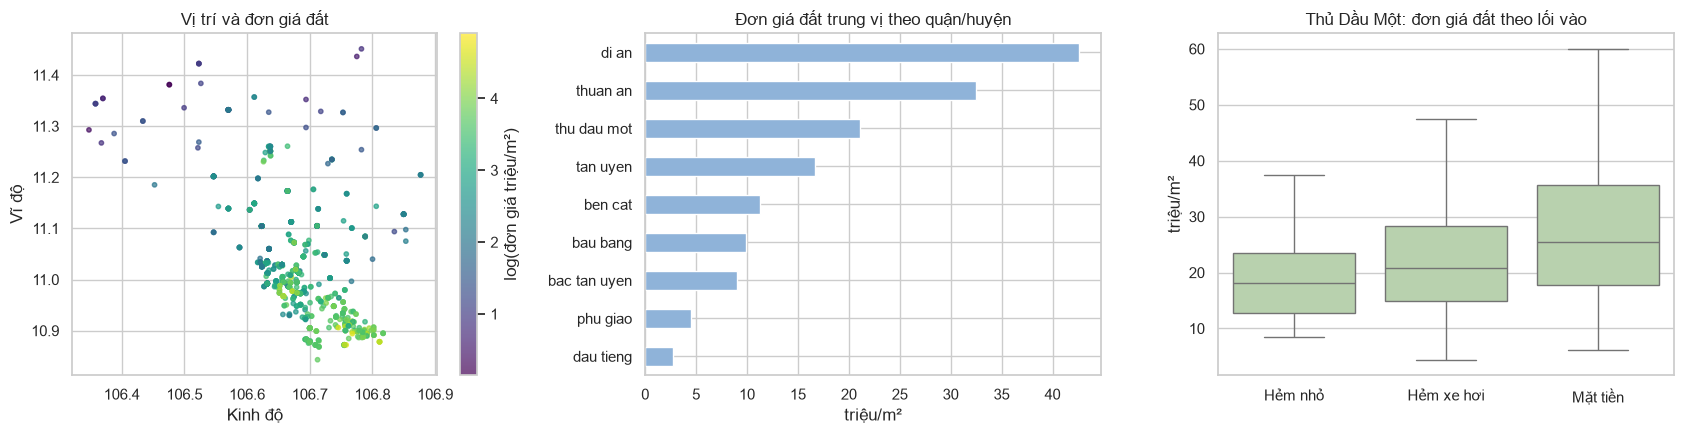

Thủ Dầu Một – đơn giá đất trung vị theo phường (≥ 8 lô):


,so_lo,gia_tv,don_gia_tv,dt_tv
phuong,,,,
Chánh Nghĩa,16,9.0,64.7,131.5
Hiệp Thành,32,3.5,28.8,113.5
Phú Thọ,11,4.3,27.8,167.0
Phú Lợi,43,3.1,27.1,110.0
Phú Tân,14,3.4,26.4,148.0
Phú Mỹ,45,3.3,24.5,134.0
Hoà Phú,14,3.8,23.8,150.0
Phú Hòa,32,3.8,21.7,150.0
Định Hoà,41,2.6,18.9,150.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sc = axes[0].scatter(df["lon"], df["lat"], c=np.log(df["don_gia"]), cmap="viridis", s=10, alpha=0.7)
plt.colorbar(sc, ax=axes[0]).set_label("log(đơn giá triệu/m²)"); axes[0].set(title="Vị trí và đơn giá đất", xlabel="Kinh độ", ylabel="Vĩ độ")
q = df.groupby("quan").agg(so_lo=("y", "size"), don_gia_tv=("don_gia", "median")).query("so_lo >= 15").sort_values("don_gia_tv")
q["don_gia_tv"].plot.barh(ax=axes[1], color="#8fb3d9"); axes[1].set(title="Đơn giá đất trung vị theo quận/huyện", xlabel="triệu/m²", ylabel="")
lv = df.dropna(subset=["cap_loi_vao"]).assign(cap=lambda d: np.where(d["cap_loi_vao"] >= 5, "Mặt tiền", np.where(d["cap_loi_vao"] >= 2, "Hẻm xe hơi", "Hẻm nhỏ")))
sns.boxplot(data=lv[lv["tdm"] == 1], x="cap", y="don_gia", order=["Hẻm nhỏ", "Hẻm xe hơi", "Mặt tiền"], showfliers=False, ax=axes[2], color="#b6d7a8")
axes[2].set(title="Thủ Dầu Một: đơn giá đất theo lối vào", xlabel="", ylabel="triệu/m²")
plt.tight_layout(); plt.show()
tdm = df[df["tdm"] == 1]
TEN_PH = {ten_phuong(p): re.sub(r"^(Phường|Xã|Thị trấn)\s*", "", p) for p in raw_ct["phuong"].dropna().unique()}
print("Thủ Dầu Một – đơn giá đất trung vị theo phường (≥ 8 lô):")
display(tdm.assign(phuong=tdm["phuong"].map(lambda k: TEN_PH.get(k, k))).groupby("phuong").agg(so_lo=("y", "size"), gia_tv=("gia_ty", "median"), don_gia_tv=("don_gia", "median"), dt_tv=("dt_dat", "median"))
        .query("so_lo >= 8").sort_values("don_gia_tv", ascending=False).round(1))

**Quan sát:** đơn giá đất giảm rõ từ lõi đô thị (Thủ Dầu Một, Thuận An, Dĩ An) ra các huyện phía bắc; trong Thủ Dầu Một, đất mặt tiền có đơn giá cao hơn hẳn đất trong hẻm. Các quan hệ này giống nhà phố, nên ta dùng lại cùng loại đặc trưng.

## Bước 4: Mô hình
Chia tập test 20% theo nhóm (riêng cho Thủ Dầu Một, nơi cần định giá); kiểm định chéo 5-fold lặp 3 lần chia theo nhóm trên tập train.

| Mô hình | Ý tưởng |
|---|---|
| Baseline | Đơn giá trung vị của phường × diện tích |
| Ridge | Hồi quy tuyến tính trên log(đơn giá) |
| LightGBM | Gradient boosting |
| LightGBM + chữ | LightGBM xếp chồng với mô hình TF-IDF trên mô tả tin |

Đặc trưng: diện tích, ngang, dài, mặt tiền, cấp lối vào, độ rộng đường/hẻm, nền dự án / khu dân cư, thổ cư toàn bộ, sổ riêng, sổ chung, lô góc, nở hậu, kinh doanh được, bán gấp, tọa độ, khoảng cách trung tâm, **giá đất khu vực** (12 lô gần nhất, phường, tuyến đường – chỉ tính trên tập học).

In [5]:
DAC_TRUNG = ["log_dt", "ngang", "dai", "mat_tien_duong", "cap_loi_vao", "hem_rong", "nen_du_an", "tho_cu_toan_bo", "so_rieng", "so_chung",
             "t_goc", "t_no_hau", "t_kinh_doanh", "t_ban_gap", "t_trung_tam", "lat", "lon", "kc_trung_tam_km"]
lgb = lambda: LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=12, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.7, verbose=-1, random_state=0, n_jobs=1)
MH = {"Baseline (đơn giá phường)": lambda: BaselineDonGiaPhuong(),
      "Ridge": lambda: MoHinhGia(RidgeCV(alphas=np.logspace(-2, 3, 30)), DAC_TRUNG, chuan_hoa=True, muc_tieu="don_gia"),
      "LightGBM": lambda: MoHinhGia(lgb(), DAC_TRUNG, muc_tieu="don_gia"),
      "LightGBM + chữ": lambda: XepChongChu(MoHinhGia(lgb(), DAC_TRUNG + ["t_chu"], muc_tieu="don_gia"))}

tdm_idx = df.index[df["tdm"] == 1]
_, vt = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(tdm_idx, groups=df.loc[tdm_idx, "nhom"]))
nhom_test = set(df.loc[tdm_idx[vt], "nhom"])
df["tap"] = np.where(df["nhom"].isin(nhom_test), "test", "train")
tr, te = df[df["tap"] == "train"].reset_index(drop=True), df[df["tap"] == "test"].reset_index(drop=True)
print(f"Train {len(tr)} lô (TDM {tr['tdm'].sum()}) | Test {len(te)} lô Thủ Dầu Một")

OOF = {k: du_doan_cheo_lap(f, tr, so_lan=SO_LAN) for k, f in MH.items()}
m_tdm = tr["tdm"].to_numpy() == 1
bang_cv = bang_danh_gia(tr, OOF, m_tdm).sort_values("MAPE (%)")
print("Kiểm định chéo – các lô Thủ Dầu Một trong tập train:"); display(bang_cv.round(2))
display(bang_danh_gia(tr, OOF, np.ones(len(tr), bool)).sort_values("MAPE (%)").round(2).rename_axis("Toàn vùng"))

Train 858 lô (TDM 315) | Test 72 lô Thủ Dầu Một


Kiểm định chéo – các lô Thủ Dầu Một trong tập train:


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
LightGBM,25.85,22.94,28.84,18.51,29.95,52.06,1.51,0.55,315.0
LightGBM + chữ,25.86,22.98,28.84,17.51,28.68,53.86,1.51,0.50,315.0
Ridge,26.03,23.10,29.19,20.69,27.30,48.47,1.57,0.51,315.0
Baseline (đơn giá phường),38.37,34.01,43.14,28.29,16.83,35.03,2.05,0.44,315.0


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Toàn vùng,,,,,,,,,
Ridge,28.45,26.56,30.42,21.88,25.72,45.92,1.31,0.73,858.0
LightGBM + chữ,29.12,27.09,31.19,20.72,25.33,48.91,1.31,0.72,858.0
LightGBM,29.19,27.17,31.27,20.93,26.11,48.10,1.31,0.74,858.0
Baseline (đơn giá phường),44.54,39.80,49.52,27.09,19.31,37.10,1.80,0.58,858.0


In [6]:
APE = {k: sai_so_tung_can(tr, P)[m_tdm] for k, P in OOF.items()}
g = tr.loc[m_tdm, "nhom"].to_numpy()
UV = ["Ridge", "LightGBM", "LightGBM + chữ"]                     # xếp từ đơn giản tới phức tạp
tot = min(UV, key=lambda k: APE[k].mean())
dong = []
for k in UV:
    lo, hi = ktc_bootstrap(APE[k] - APE[tot], g) if k != tot else (0.0, 0.0)
    dong.append({"Mô hình": k, "MAPE (%)": APE[k].mean(), "Chênh so với tốt nhất": APE[k].mean() - APE[tot].mean(), "KTC thấp": lo, "KTC cao": hi})
so_sanh = pd.DataFrame(dong).set_index("Mô hình")
ten_chon = next(k for k in UV if so_sanh.loc[k, "KTC thấp"] <= 0)
lo, hi = ktc_bootstrap(APE["Baseline (đơn giá phường)"] - APE[ten_chon], g)
display(so_sanh.round(2))
print(f"Chọn: {ten_chon} (đơn giản nhất không kém mô hình tốt nhất '{tot}' một cách có ý nghĩa). "
      f"So với baseline: giảm {np.mean(APE['Baseline (đơn giá phường)'] - APE[ten_chon]):.2f} điểm % MAPE (KTC 95% {lo:+.2f} … {hi:+.2f})")

m = MH[ten_chon]().fit(tr, tr["y"])
p_te = m.predict(te)
bang_test = bang_danh_gia(te, {ten_chon: p_te, "Baseline": MH["Baseline (đơn giá phường)"]().fit(tr, tr["y"]).predict(te)}, np.ones(len(te), bool))
print(f"Tập test ({len(te)} lô Thủ Dầu Một chưa từng thấy):"); display(bang_test.round(2))
i_max = np.argmax(np.abs(np.exp(te["y"]) - np.exp(p_te)))
print(f"Ghi chú: R² tính trên giá tỷ đồng rất nhạy với vài lô lớn; lô lệch nhiều nhất: giá rao {te['gia_ty'][i_max]:.1f} tỷ, "
      f"{te['dt_dat'][i_max]:.0f} m², dự đoán {np.exp(p_te[i_max]):.1f} tỷ. MAPE/MdAPE (theo %) phản ánh đúng hơn.")

,MAPE (%),Chênh so với tốt nhất,KTC thấp,KTC cao
Mô hình,,,,
Ridge,26.03,0.19,-1.23,1.65
LightGBM,25.85,0.00,0.00,0.00
LightGBM + chữ,25.86,0.01,-0.74,0.76


Chọn: Ridge (đơn giản nhất không kém mô hình tốt nhất 'LightGBM' một cách có ý nghĩa). So với baseline: giảm 12.33 điểm % MAPE (KTC 95% +9.17 … +15.70)
Tập test (72 lô Thủ Dầu Một chưa từng thấy):


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (tỷ),R²,Số căn
Ridge,30.20,22.27,39.80,18.47,27.78,52.78,1.09,0.70,72.0
Baseline,40.37,28.48,55.46,24.50,22.22,41.67,1.51,0.29,72.0


Ghi chú: R² tính trên giá tỷ đồng rất nhạy với vài lô lớn; lô lệch nhiều nhất: giá rao 20.0 tỷ, 292 m², dự đoán 8.6 tỷ. MAPE/MdAPE (theo %) phản ánh đúng hơn.


**Đọc kết quả:** so sánh với baseline cho biết mô hình học được gì hơn "lấy đơn giá trung bình của phường": tác động của mặt tiền / hẻm, kích thước lô, pháp lý và vị trí chi tiết trong phường. Sai số định giá đất thường **lớn hơn căn hộ** vì mỗi lô đất là duy nhất và người bán tự đặt giá.

## Bước 5: Khoảng giá 80% và chẩn đoán giá rao
Khoảng giá được hiệu chỉnh từ sai số kiểm định chéo **theo mức giá** (4 nhóm theo giá dự đoán), như notebook nhà phố. Sau đó kiểm tra độ phủ trên tập test.

In [7]:
P = OOF[ten_chon][:, m_tdm]
NGUONG = np.quantile(P.mean(axis=0), [0.25, 0.5, 0.75]).tolist()
r = (tr.loc[m_tdm, "y"].to_numpy()[None, :] - P).ravel()
KHOANG = hieu_chinh_khoang(r, muc_gia(P.ravel(), NGUONG)); KHOANG["nguong"] = NGUONG
q = phan_vi_cho(muc_gia(p_te, NGUONG), KHOANG)
phu = np.mean((te["y"] >= p_te + q["q10"]) & (te["y"] <= p_te + q["q90"])) * 100
print(f"Độ phủ khoảng 80% trên tập test: {phu:.1f}% ({len(te)} lô)")
display(pd.DataFrame({k: {"Biên độ 80%": f"{(np.exp(v['q10']) - 1) * 100:+.0f}% … {(np.exp(v['q90']) - 1) * 100:+.0f}%"} for k, v in sorted(KHOANG["nhom"].items())}).T.rename_axis("Mức giá (0 = rẻ nhất)"))

# Chẩn đoán giá rao các lô ở Thủ Dầu Một: dùng dự đoán CHÉO (lô đang chẩn đoán không nằm trong tập học)
tdm_all = df[df["tdm"] == 1].reset_index(drop=True)
P_all = du_doan_cheo_lap(MH[ten_chon], df, so_lan=SO_LAN)[:, df["tdm"].to_numpy() == 1].mean(axis=0)
qa = phan_vi_cho(muc_gia(P_all, NGUONG), KHOANG)
tdm_all["gia_du_doan_ty"] = np.exp(P_all)
tdm_all["khoang_thap_ty"], tdm_all["khoang_cao_ty"] = np.exp(P_all + qa["q10"]), np.exp(P_all + qa["q90"])
lech = tdm_all["y"] - P_all
tdm_all["chan_doan"] = np.select([lech < qa["q10"], lech > qa["q90"]], ["Rẻ hơn thị trường", "Cao hơn thị trường"], "Hợp lý")
# Lô rất lớn (> 1.000 m², ~1% dữ liệu): quá ít mẫu để mô hình học đúng, dự đoán dễ ngoại suy sai -> không chẩn đoán
tdm_all.loc[tdm_all["dt_dat"] > 1000, "chan_doan"] = "Lô lớn – không chẩn đoán"
print("Lô > 1.000 m² không được chẩn đoán:", int((tdm_all["dt_dat"] > 1000).sum()))
display(tdm_all["chan_doan"].value_counts().to_frame("Số lô"))
tdm_all[["id", "nguon", "url", "phuong", "duong", "dt_dat", "ngang", "dai", "gia_ty", "don_gia", "gia_du_doan_ty", "khoang_thap_ty", "khoang_cao_ty", "chan_doan"]] \
    .round(3).to_csv(KET_QUA / "output_dat.csv", index=False, encoding="utf-8-sig")

Độ phủ khoảng 80% trên tập test: 79.2% (72 lô)


,Biên độ 80%
Mức giá (0 = rẻ nhất),
0,-19% … +52%
1,-31% … +40%
2,-30% … +48%
3,-33% … +98%


Lô > 1.000 m² không được chẩn đoán: 10


,Số lô
chan_doan,
Hợp lý,299
Rẻ hơn thị trường,39
Cao hơn thị trường,39
Lô lớn – không chẩn đoán,10


## Bước 6: Mô hình rút gọn cho trang web và lưu kết quả
Trang web không chạy được LightGBM, nên dùng mô hình rút gọn cùng cách với căn hộ: **đơn giá đất của phường** (co về quận khi phường ít tin) + hồi quy Ridge trên vài thông số người dùng nhập được (diện tích, ngang, lối vào, độ rộng đường, nền dự án, thổ cư toàn bộ, sổ riêng). Mô hình rút gọn cũng được kiểm định chéo theo nhóm để biết sai số thật của trang web.

In [8]:
import joblib
WEB = ["log_dt", "ngang", "cap_loi_vao", "hem_rong", "nen_du_an", "tho_cu_toan_bo", "so_rieng"]
M_CO = 5.0
class DatWeb(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        u = np.asarray(y) - np.log(X["dt_dat"].to_numpy())
        self.g_ = float(np.median(u))
        qn = pd.Series(u).groupby(X["quan"].values).agg(["sum", "count"]); self.q_ = ((qn["sum"] + M_CO * self.g_) / (qn["count"] + M_CO)).to_dict()
        k = (X["quan"] + "|" + X["phuong"].astype(str)).values
        ph = pd.DataFrame({"u": u, "k": k, "q": X["quan"].values}).groupby("k").agg(sum=("u", "sum"), count=("u", "size"), q=("q", "first"))
        self.ph_ = {kk: (r_["sum"] + M_CO * self.q_.get(r_["q"], self.g_)) / (r_["count"] + M_CO) for kk, r_ in ph.iterrows()}
        self.r_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0)).fit(self._X(X), u - self._nen(X))
        return self
    def _X(self, X):
        Z = X[WEB].astype(float).copy(); Z["ngang"] = Z["ngang"].clip(upper=30); Z["hem_rong"] = Z["hem_rong"].clip(upper=30); return Z
    def _nen(self, X):
        q = X["quan"].map(self.q_).fillna(self.g_)
        return (X["quan"] + "|" + X["phuong"].astype(str)).map(self.ph_).fillna(q).to_numpy(float)
    def predict(self, X):
        return self._nen(X) + self.r_.predict(self._X(X)) + np.log(X["dt_dat"].to_numpy())

P_web = du_doan_cheo_lap(DatWeb, df, so_lan=SO_LAN)
cv_web = bang_danh_gia(df, {"Web": P_web}, df["tdm"].to_numpy() == 1).iloc[0]
print(f"Mô hình web – kiểm định chéo theo nhóm, lô Thủ Dầu Một: MAPE {cv_web['MAPE (%)']:.1f}% (KTC {cv_web['MAPE thấp (95%)']:.1f}–{cv_web['MAPE cao (95%)']:.1f})")
web = DatWeb().fit(df, df["y"])
imp, sc, rg = web.r_.named_steps["simpleimputer"], web.r_.named_steps["standardscaler"], web.r_.named_steps["ridge"]
r_web = (df.loc[df["tdm"] == 1, "y"].to_numpy()[None, :] - P_web[:, df["tdm"].to_numpy() == 1]).ravel()
ten_hien = (raw_ct.assign(k=raw_ct["quan_huyen"].map(ten_quan) + "|" + raw_ct["phuong"].map(ten_phuong))
            .dropna(subset=["phuong"]).groupby("k")["phuong"].first().str.replace(r"^(Phường|Xã|Thị trấn)\s*", "", regex=True).to_dict())
so_lo = (df["quan"] + "|" + df["phuong"].astype(str)).value_counts().to_dict()
phuong_web = [{"ma": k, "ten": ten_hien.get(k, k.split("|")[1].title()), "quan": k.split("|")[0], "so_lo": int(so_lo.get(k, 0)), "log_don_gia": round(v, 4)}
              for k, v in web.ph_.items() if so_lo.get(k, 0) >= 3]
json.dump({"features": WEB, "medians": imp.statistics_.tolist(), "scaler": {"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist()},
           "coef": rg.coef_.tolist(), "intercept": float(rg.intercept_), "clip": {"ngang": 30, "hem_rong": 30},
           "phuong": sorted(phuong_web, key=lambda d: (d["quan"] != "thu dau mot", d["ten"])), "quan": {k: round(v, 4) for k, v in web.q_.items()},
           "toan_vung": round(web.g_, 4), "cv_mape_tdm": round(float(cv_web["MAPE (%)"]), 1),
           "phan_vi_sai_so": {k: float(np.quantile(r_web, qq)) for k, qq in {"q10": .1, "q25": .25, "q75": .75, "q90": .9}.items()},
           "mo_hinh_day_du": ten_chon, "mo_hinh_day_du_mape_tdm": round(float(bang_cv.loc[ten_chon, "MAPE (%)"]), 1),
           "so_lo": len(df), "so_lo_tdm": int(df["tdm"].sum()), "ngay_du_lieu": str(raw_ct["ngay_thu_thap"].iloc[0])},
          open(MODEL_DIR / "mo_hinh_gia_dat.json", "w", encoding="utf-8"), ensure_ascii=False)
mo_hinh_cuoi = MH[ten_chon]().fit(df, df["y"])
joblib.dump({"model": mo_hinh_cuoi, "ten": ten_chon, "khoang_theo_muc": KHOANG, "dac_trung": DAC_TRUNG}, MODEL_DIR / "mo_hinh_gia_dat.joblib")
ghi = lambda b: b.round(3).reset_index(names="Mô hình").to_dict("records")
json.dump({"ten_mo_hinh": ten_chon, "kiem_dinh_cheo_tdm": ghi(bang_cv), "chon_mo_hinh": ghi(so_sanh.astype(float)), "test_tdm": ghi(bang_test),
           "do_phu_test_80": round(phu, 1), "mo_hinh_web_mape_tdm": round(float(cv_web["MAPE (%)"]), 2),
           "so_lo": {"tat_ca": len(df), "tdm": int(df["tdm"].sum()), "phu_hoa": int(df["phu_hoa"].sum())}},
          open(MODEL_DIR / "danh_gia_mo_hinh_dat.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
df.drop(columns=["van_ban", "mo_ta"]).to_csv(PROC / "dat_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Đã lưu: model/mo_hinh_gia_dat.joblib, model/mo_hinh_gia_dat.json, model/danh_gia_mo_hinh_dat.json, ket_qua/output_dat.csv, data/processed/dat_da_xu_ly.csv")

Mô hình web – kiểm định chéo theo nhóm, lô Thủ Dầu Một: MAPE 28.6% (KTC 25.8–31.7)
Đã lưu: model/mo_hinh_gia_dat.joblib, model/mo_hinh_gia_dat.json, model/danh_gia_mo_hinh_dat.json, ket_qua/output_dat.csv, data/processed/dat_da_xu_ly.csv


## Kết luận
- Mô hình định giá **đất ở** (thổ cư, nền dự án) học trên tin bán đất thật của Chợ Tốt và alonhadat, cùng quy trình làm sạch – chống rò rỉ – chọn mô hình như nhà phố và căn hộ. Kết quả ở Bước 4–5.
- Mỗi lô đất ở Thủ Dầu Một có giá ước lượng, khoảng 80% và chẩn đoán *rẻ / hợp lý / cao* (`ket_qua/output_dat.csv`).
- Trang demo có mục **Định giá đất** dùng mô hình rút gọn (sai số đã kiểm định ở Bước 6).

**Hạn chế:** giá là **giá rao**; tin alonhadat không có tọa độ riêng (dùng tọa độ tuyến đường/phường); quy hoạch, lộ giới và hướng đất chưa có trong dữ liệu; đất nông nghiệp/công nghiệp quá ít tin nên không định giá.